In [ ]:
# import statements

import PyPhenom as ppi
import numpy as np
#from PIL import Image
import matplotlib.pyplot as plt
from lmfit import Model, models, minimize, Minimizer, create_params
#from scipy.optimize import minimize
import warnings


In [ ]:
# helper functions

def auto_correlation(frame):
    """
    Returns the computed auto_correlation for a given frame.

    Parameter frame: an SEM image
    """

    ft = np.fft.fft2(frame)
    autocorr = np.fft.ifft2(ft * np.conjugate(ft))
    return np.fft.fftshift(autocorr).real


def gaussian2d_with_offset(x, y, amplitude, centerx, centery, sigmax, sigmay, correlation, offset):
    """
    Returns a bivariate normal distribution equation for a given set of parameters.

    Parameter x: a numpy meshgrid representing the x-axis
    Parameter y: a numpy meshgrid representing the y-axis
    Parameter amplitude: a number representing the amplitude of the distribution
    Parameter centerx: a number representing the mean value of the x-values
    Parameter centery: a number representing the mean value of the y-values
    Parameter sigmax: a number representing the standard deviation in the x-direction
    Parameter sigmay: a number representing the standard deviation in the y-direction
    Parameter correlation: a number representing the correlation between the two indepedent variables x and y
    Parameter offset: a number representing the offset between the distribution and the x = y = 0 plane
    """

    xterm = (x - centerx) / sigmax 
    yterm = (y - centery) / sigmay
    exponent = (-1 / (2 * (1 - correlation**2))) * (xterm**2 + yterm**2 - 2 * correlation * xterm * yterm)
    constant = amplitude / (2 * np.pi * sigmax * sigmay * np.sqrt(1 - correlation**2))
    return constant * np.exp(exponent) + offset


def covariance_matrix(ac): # if code too slow, consider fitting with scipy instead of lmfit
    """
    Returns the computed covariance matrix given the auto_correlation data.

    Parameter ac: a 2d array with values corresponding to the auto_correlation data at each position i,j
    """

    model = Model(gaussian2d_with_offset, independent_vars=['x', 'y']) # creates a model using lmfit that the data is going to be fitted to

    nrows = len(ac)
    ncols = len(ac[0])

    x_val, y_val = np.meshgrid(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows)) # creates the x and y array values

    mod = models.Gaussian2dModel() 
    pars = mod.guess(ac.flatten(), x_val.flatten(), y_val.flatten()) # uses lmfit Gaussian2dModel to get initial parameter guesses
    pars.add("offset", value = np.min(ac)) # uses the minimum value of the autocorrelation data as a offset value guess
    pars.add("correlation", value = 0, min = -1, max = 1) # uses 0 as a correlation value guess

    result = model.fit(ac, x = x_val, y = y_val, params = pars) # uses the above parameters and  model to fit the data
    #print(result.fit_report())

    # shows the contour plot of the fit plotted on top of the contour plot of the data
    #fig, ax = plt.subplots()
    #ax.contour(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows), ac)
    #ax.contour(np.linspace(0, ncols, ncols), np.linspace(0, nrows, nrows), result.best_fit)
    #plt.show()

    covarxx = result.best_values["sigmax"]**2
    covarxy = result.best_values["correlation"] * result.best_values["sigmax"] * result.best_values["sigmay"]
    covaryy = result.best_values["sigmay"]**2
    #covar_matrix = [[covarxx, covarxy], [covarxy, covaryy]] # Calculates covariance matrix
    covar_matrix = {"covarxx": covarxx, "covaryy": covaryy, "covarxy": covarxy}
    
    return covar_matrix


def minimum(x, y, degree):
    """
    Calculates the minimum value and the position of its occurence given a data set x and y 
    and the degree of the polynomial to be fitted.

    Parameter x: a 1D list of x-coordinates
    Parameter y: a 1D list of corresponding y-coordinates
    Parameter degree: an int representing the maximum degree of the polynomial to be fitted
    """

    warnings.filterwarnings("error", category=np.RankWarning)

    eqn = None

    while eqn is None:
        try:
            coeff = np.polyfit(x, y, degree) # fits the data to a polynomial equation that is a good fit (doesn't give a RankWarning)
            eqn = np.poly1d(coeff)  

        except:                                                 
            degree = degree - 1

    derivative = eqn.deriv()
    local_mins = np.roots(derivative.c)
    min_vals = []

    for val in local_mins:
        min_vals.append(eqn(val))

    small_val = min(min_vals)
    small_pos = local_mins[min_vals.index(small_val)]

    return {"min_val": small_val.real, "min_x": small_pos.real, "fitted_eqn": eqn}


def focus(phenom, type, num_pic, val_min, val_max):
    """
    Returns the working distance, x-direction stigmate, or y-direction stigmate corresponding to the best image.
    The value returned depends on the parameters type, num_pic, val_min, and val_max.

    Parameter phenom: a Phenom object
    Parameter type: the string "wd", "xst", or "yst", corresponding to working distance, x-direction stigmate, and y-direction stigmate
    Parameter num_pic: the number of pictures taken
    Parameter val_min: the minimum value of wd, xst, or yst that a picture is taken at
    Parameter val_max: the maximum value of wd, xst, or yst that a picture is taken at
    """
    
    val_range = np.linspace(val_min, val_max, num_pic) # creates equally spaced values that pictures are taken at
    covarxx_data = []
    covaryy_data = []
    covarxy_data = []

    xdim = 256 # x and y dimensions of image taken
    ydim = 256
    stack = 8
    HDR = False
    scale = 1. #Set to a value < 1 to zoom in on a part of the image - centered

    st_og = phenom.GetSemStigmate()

    for val in val_range:
        print(val)
        if type == "wd":
            phenom.SetSemWD(val)

        elif type == "xst":
            phenom.SetSemStigmate(ppi.Position(val, st_og.y))

        elif type == "yst":
            phenom.SetSemStigmate(ppi.Position(st_og.x, val))

        phenom.SemAutoContrastBrightness()
        acq = phenom.SemAcquireImage(xdim ,ydim, stack, ppi.DetectorMode.All, HDR, scale)

        img_array = np.array(acq.image) # converts image into an array
        acdata = auto_correlation(img_array) # calculates the auto_correlation data
        covar_data = covariance_matrix(acdata) # calculates the covariance matrix
        print(covar_data)

        if type == "wd":
            covarxx_data.append(covar_data["covarxx"]) # finds the covarxx and covaryy data for working distance calibration
            covaryy_data.append(covar_data["covaryy"])

        elif type == "xst" or type == "yst":
            covarxy_data.append(covar_data["covarxy"]) # finds the covarxy data for stigmate calibration

    if type == "wd": # calculates the minimum and the new range for working distance calibration
        x_data = minimum(val_range, covarxx_data, 4)
        y_data = minimum(val_range, covaryy_data, 4)
        range_bottom = max((min(x_data["min_x"], y_data["min_x"]) - ((val_max - val_min) / 3)), val_min) # can change 2 depending on testing ig
        range_top = min((max(x_data["min_x"], y_data["min_x"]) + ((val_max - val_min) / 3)), val_max) # ^
        return {"range_bottom": range_bottom, "range_top": range_top, "x_data": x_data, "y_data": y_data}

    elif type == "xst" or type == "yst": # calculates the minimum and the new range for stigmate calibration
        data = minimum(val_range, covarxy_data, 4) 
        range_bottom = max(data["min_x"] - ((val_max - val_min) / 3), val_min) # can change 2 depending on testing ig
        range_top = min(data["min_x"] + ((val_max - val_min) / 3), val_max) # ^
        return {"range_bottom": range_bottom, "range_top": range_top, "data": data}


def auto_focus(phenom, num_pic, wd_val_min, wd_val_max, xst_val_min, xst_val_max, yst_val_min, yst_val_max):
    """
    Sets the working distance, x-direction stigmate, and y-direction stigmate to the values needed for a focused image.

    Parameter phenom: a Phenom object
    Parameter num_pic: the number of pictures taken
    Parameter val_min: the minimum value of wd, xst, or yst that a picture is taken at
    Parameter val_max: the maximum value of wd, xst, or yst that a picture is taken at
    """

    xwd_prev_val = None
    xwd_cur_val = None
    xwd_sig = None
    xwd_eqn = None
    ywd_prev_val = None
    ywd_cur_val = None
    ywd_sig = None
    ywd_eqn = None
    wd_small = 0.001

    xst_prev_val = None
    xst_cur_val = None
    yst_prev_val = None
    yst_cur_val = None
    st_small = 0.001 

    while True:
        new_vals = focus(phenom, "wd", num_pic, wd_val_min, wd_val_max) # call with wd data
        xwd_cur_val = new_vals["x_data"]["min_x"]
        ywd_cur_val = new_vals["y_data"]["min_x"]
        xwd_sig = new_vals["x_data"]["min_val"]
        xwd_eqn = new_vals["x_data"]["fitted_eqn"]
        ywd_sig = new_vals["y_data"]["min_val"]
        ywd_eqn = new_vals["y_data"]["fitted_eqn"]
        print("xwd: " + str(xwd_cur_val) + ", ywd: " + str(ywd_cur_val) + ", xsig: " + str(xwd_sig) + ", ysig: " + str(ywd_sig) + ", xeqn: " + str(xwd_eqn) + ", yeqn: " + str(ywd_eqn))

        if (xwd_prev_val is not None and ywd_prev_val is not None and (np.absolute(xwd_cur_val - xwd_prev_val) < wd_small) and 
            (np.absolute(ywd_cur_val - ywd_prev_val) < wd_small)): # repeat until the change in values is small
            break 

        xwd_prev_val = xwd_cur_val 
        ywd_prev_val = ywd_cur_val
        wd_val_min = new_vals["range_bottom"]
        wd_val_max = new_vals["range_top"]

    if round(xwd_cur_val, 4) == round(ywd_cur_val, 4):
        phenom.SetSemWD(round(xwd_cur_val, 4))

    else: # if the wd for x and y aren't the same, then compare the sigy value at xwd with the sigy value at ywd and 
        ysig_xwd = xwd_eqn(xwd_cur_val)                 # the sigx value at ywd with the sigx value at xwd and calculate the difference
        xsig_ywd = ywd_eqn(ywd_cur_val)                 # and choose the wd with the smallest difference
        y_diff = np.absolute(ysig_xwd - ywd_sig)
        x_diff = np.absolute(xsig_ywd - xwd_sig)

        if min(x_diff, y_diff) == x_diff:
            phenom.SetSemWD(round(xwd_cur_val, 4))
    
        else:
            phenom.SetSemWD(round(ywd_cur_val, 4))

    #while True:
     #   new_vals = focus(phenom, "xst", num_pic, xst_val_min, xst_val_max) # call with xst data
    #    xst_cur_val = new_vals["data"]["min_x"]
     #   print("xst: " + str(xst_cur_val) + ", xysig: " + str(new_vals["data"]["min_val"]) + ", eqn: " + str(new_vals["data"]["fitted_eqn"]))

      #  if xst_prev_val is not None and (np.absolute(xst_cur_val - xst_prev_val) < st_small): # repeat until the change in values is small
     #       break 

   #     xst_prev_val = xst_cur_val 
     #   xst_val_min = new_vals["range_bottom"]
    #    xst_val_max = new_vals["range_top"]

   # phenom.SetSemStigmate(ppi.Position(xst_cur_val, st_og.y))

    #while True:
    #    new_vals = focus(phenom, "yst", num_pic, yst_val_min, yst_val_max) # call with yst data
    #    yst_cur_val = new_vals["data"]["min_x"]

     #   if yst_prev_val is not None and (np.absolute(yst_cur_val - yst_prev_val) < st_small): # repeat until the change in values is small
    #        break 

    #    yst_prev_val = yst_cur_val 
    #    yst_val_min = new_vals["range_bottom"]
   #     yst_val_max = new_vals["range_top"]

  #  phenom.SetSemStigmate(ppi.Position(st_og.x, xst_cur_val))

In [ ]:
pars = create_params(x=dict(value=0.0, vary=True, min=-10, max=10, brute_step=0.25)) # create the wd range to scan over

# define func that takes input (given by optimization func)
def obj_func(wd): # need to change to taken pars as parameter (wd = x range)
    phenom.SetSemWD(wd)
    xdim = 256 # x and y dimensions of image taken
    ydim = 256
    stack = 8
    HDR = False
    scale = 1. #Set to a value < 1 to zoom in on a part of the image - centered

    phenom.SemAutoContrastBrightness()
    acq = phenom.SemAcquireImage(xdim ,ydim, stack, ppi.DetectorMode.All, HDR, scale)

    img_array = np.array(acq.image) # converts image into an array
    acdata = auto_correlation(img_array) # calculates the auto_correlation data
    return covariance_matrix(acdata)["covarxx"] # calculates the covariance matrix # possibly ravel if matrix # could possibly mnimize both x and y if put in list

fitter = Minimizer(obj_func, pars)
result = fitter.minimize(method='brute')

print(result.brute_x0)
print(result.brute_fval)

-0.5
4.75
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
x      -0.5      -10       10     None     True     None     0.25


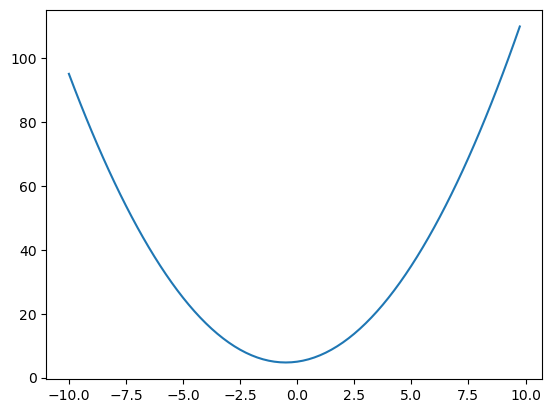

In [1]:
#import copy
from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import numpy as np
from lmfit import Minimizer, create_params, fit_report

params = create_params(x=dict(value=0.0, vary=True, min=-10, max=10, brute_step=0.25))

def quad(pars):
    p = pars.valuesdict()
    return p['x']**2 + p['x'] + 5

fitter = Minimizer(quad, params)
result = fitter.minimize(method='brute')

print(result.brute_x0)
print(result.brute_fval)

result.params.pretty_print()
vrange = np.linspace(-10, 10, 100)

plt.figure()
plt.plot(result.brute_grid, result.brute_Jout)




[-0.5 -0.5]
4.5
Name     Value      Min      Max   Stderr     Vary     Expr Brute_Step
x      -0.5      -10       10     None     True     None     0.25
y      -0.5      -10       10     None     True     None     0.25
[[[-10.   -10.   -10.   ... -10.   -10.   -10.  ]
  [ -9.75  -9.75  -9.75 ...  -9.75  -9.75  -9.75]
  [ -9.5   -9.5   -9.5  ...  -9.5   -9.5   -9.5 ]
  ...
  [  9.25   9.25   9.25 ...   9.25   9.25   9.25]
  [  9.5    9.5    9.5  ...   9.5    9.5    9.5 ]
  [  9.75   9.75   9.75 ...   9.75   9.75   9.75]]

 [[-10.    -9.75  -9.5  ...   9.25   9.5    9.75]
  [-10.    -9.75  -9.5  ...   9.25   9.5    9.75]
  [-10.    -9.75  -9.5  ...   9.25   9.5    9.75]
  ...
  [-10.    -9.75  -9.5  ...   9.25   9.5    9.75]
  [-10.    -9.75  -9.5  ...   9.25   9.5    9.75]
  [-10.    -9.75  -9.5  ...   9.25   9.5    9.75]]]
[[185.     180.3125 175.75   ... 189.8125 194.75   199.8125]
 [180.3125 175.625  171.0625 ... 185.125  190.0625 195.125 ]
 [175.75   171.0625 166.5    ... 180.5625 1

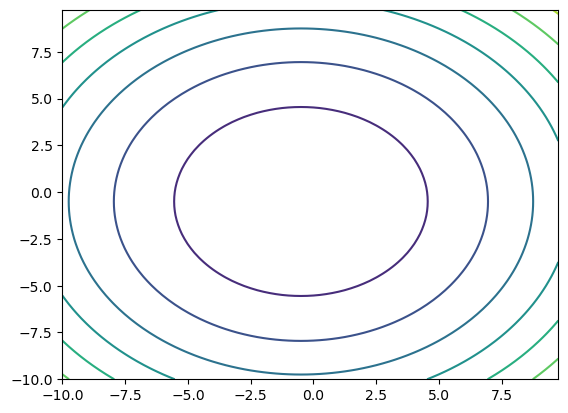

In [ ]:

from matplotlib.colors import LogNorm
import matplotlib.pyplot as plt
import numpy as np
from lmfit import Minimizer, create_params

params = create_params(x=dict(value=0.0, vary=True, min=-10, max=10, brute_step=0.25),
                       y=dict(value=0.0, vary=True, min=-10, max=10, brute_step=0.25))

def quad2d(pars):
    p = pars.valuesdict()
    return p['x']**2 + p['x'] + p['y']**2 + p['y'] + 5

fitter = Minimizer(quad2d, params)
result = fitter.minimize(method='brute')

print(result.brute_x0)
print(result.brute_fval)

result.params.pretty_print()

print(result.brute_grid)
print(result.brute_Jout)

plt.contour(result.brute_grid[0], result.brute_grid[1], result.brute_Jout)



In [52]:
# main thing 

# connect to SEM 
PhenomID = 'MVE086101-20057-F'
username = 'MVE08610120057F'
password = 'KN68X6HJQMT9'

phenom = ppi.Phenom(PhenomID, username, password)

num_pic = 10 # change later depending on testing
wd_val_min = 0.002
wd_val_max = 0.011 #0.12198 is max value
xst_val_min = -1
xst_val_max = 1
yst_val_min = -1
yst_val_max = 1

auto_focus(phenom, num_pic, wd_val_min, wd_val_max, xst_val_min, xst_val_max, yst_val_min, yst_val_max)


0.002


C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


{'covarxx': 10380.867276759862, 'covaryy': 2516.9055552921623, 'covarxy': -2118.0558086244787}
0.003
{'covarxx': 11929.40094398898, 'covaryy': 2558.740365812595, 'covarxy': -2056.2721431995446}
0.004
{'covarxx': 13711.999815707284, 'covaryy': 2471.4755528083083, 'covarxy': -1875.916623174624}
0.005
{'covarxx': 15223.755931424532, 'covaryy': 2428.058190167074, 'covarxy': -1729.7032177742983}
0.006
{'covarxx': 16062.846652399554, 'covaryy': 2306.6958519561567, 'covarxy': -1582.8000472172225}
0.007
{'covarxx': 16474.824281856243, 'covaryy': 2233.629003469127, 'covarxy': -1263.3904446884985}
0.008
{'covarxx': 13935.770066744537, 'covaryy': 2159.2084152442017, 'covarxy': -964.7249805055404}
0.009000000000000001
{'covarxx': 12014.526060534881, 'covaryy': 1894.3518224351021, 'covarxy': -878.3979539109524}
0.01
{'covarxx': 11705.763938534195, 'covaryy': 1749.431582681915, 'covarxy': -860.449997818473}
0.011
{'covarxx': 12052.756101608698, 'covaryy': 1485.1669417602307, 'covarxy': -987.72778682

C:\Users\ThermoFisher\AppData\Roaming\Python\Python311\site-packages\uncertainties\core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


{'covarxx': 15643.339264725722, 'covaryy': 2228.2946285094577, 'covarxy': -1311.2629706669309}
0.007249240003914089
{'covarxx': 16203.31072890891, 'covaryy': 2184.100673948529, 'covarxy': -1188.8095104258955}
0.0077180850034248285
{'covarxx': 13997.948803479876, 'covaryy': 2106.425433635956, 'covarxy': -1010.7987609020228}
0.008186930002935567
{'covarxx': 12729.774216297104, 'covaryy': 2067.4062608946233, 'covarxy': -940.3304635511279}
0.008655775002446306
{'covarxx': 12279.104197117887, 'covaryy': 1880.7902993502066, 'covarxy': -1029.0775360325865}
0.009124620001957044
{'covarxx': 11051.267294422223, 'covaryy': 1719.7112545049683, 'covarxy': -963.9347828364148}
0.009593465001467783
{'covarxx': 10937.509084942209, 'covaryy': 1707.4874620822818, 'covarxy': -837.6879832546911}
0.01006231000097852
{'covarxx': 12454.527069024098, 'covaryy': 1653.0899252790919, 'covarxy': -914.469813991515}
0.01053115500048926
{'covarxx': 12086.237130975655, 'covaryy': 1601.1494675274612, 'covarxy': -950.29